# Life-stage polities: results (whole database)
## How each stage is found
Share of each stage (%) found by each Wikidata field and method, over every individual with a birth and a death year. Read from the parquets of `01_life_stage_polities_export.py` (one per 1,000,000 individuals); the method is explored on a sample in `01_life_stage_polities.ipynb`. A stage is found by Wikipedia Url when at least one of its locations matched a polity's Wikipedia article, else by center coordinates (the location's Wikidata point, P625, inside a polity's borders). The total, not found included, is 100%; the three largest shares of each stage (not found aside) are in bold; a blank cell is no individual.

In [1]:
import sys
from pathlib import Path

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
EXPORT = Path('../../data/enriched_parquets/individual_life_stage_polities')
STAGES = ['early', 'active', 'late']
FIELDS = ['birthplace', 'educated at', 'residence', 'citizenship', 'work location', 'employer', 'position held', 'deathplace', 'not found']
METHODS = {'URL': 'Wikipedia Url', 'coordinates': 'Center coordinates', '—': '—'}
EXAMPLES = {  # well-known individuals who moved between polities, with Wikidata birth and death dates
    'Q5592': 'Michelangelo', 'Q131552': "Catherine de' Medici", 'Q36620': 'Tycho Brahe', 'Q47365': 'Marie Antoinette', 'Q7186': 'Marie Curie',
    'Q1001': 'Mahatma Gandhi', 'Q47737': 'Kahlil Gibran', 'Q36014': 'Ho Chi Minh', 'Q151972': 'Josephine Baker', 'Q60025': 'Hannah Arendt',
}
MAX_POLITIES = 3  # an example with more polities in one stage does not fit the table

In [2]:
stages = pl.read_parquet(EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'wikidata_field', 'method'])
print(f"{stages['qid'].n_unique():,} individuals, {stages.height:,} stages")

3,905,694 individuals, 11,463,674 stages


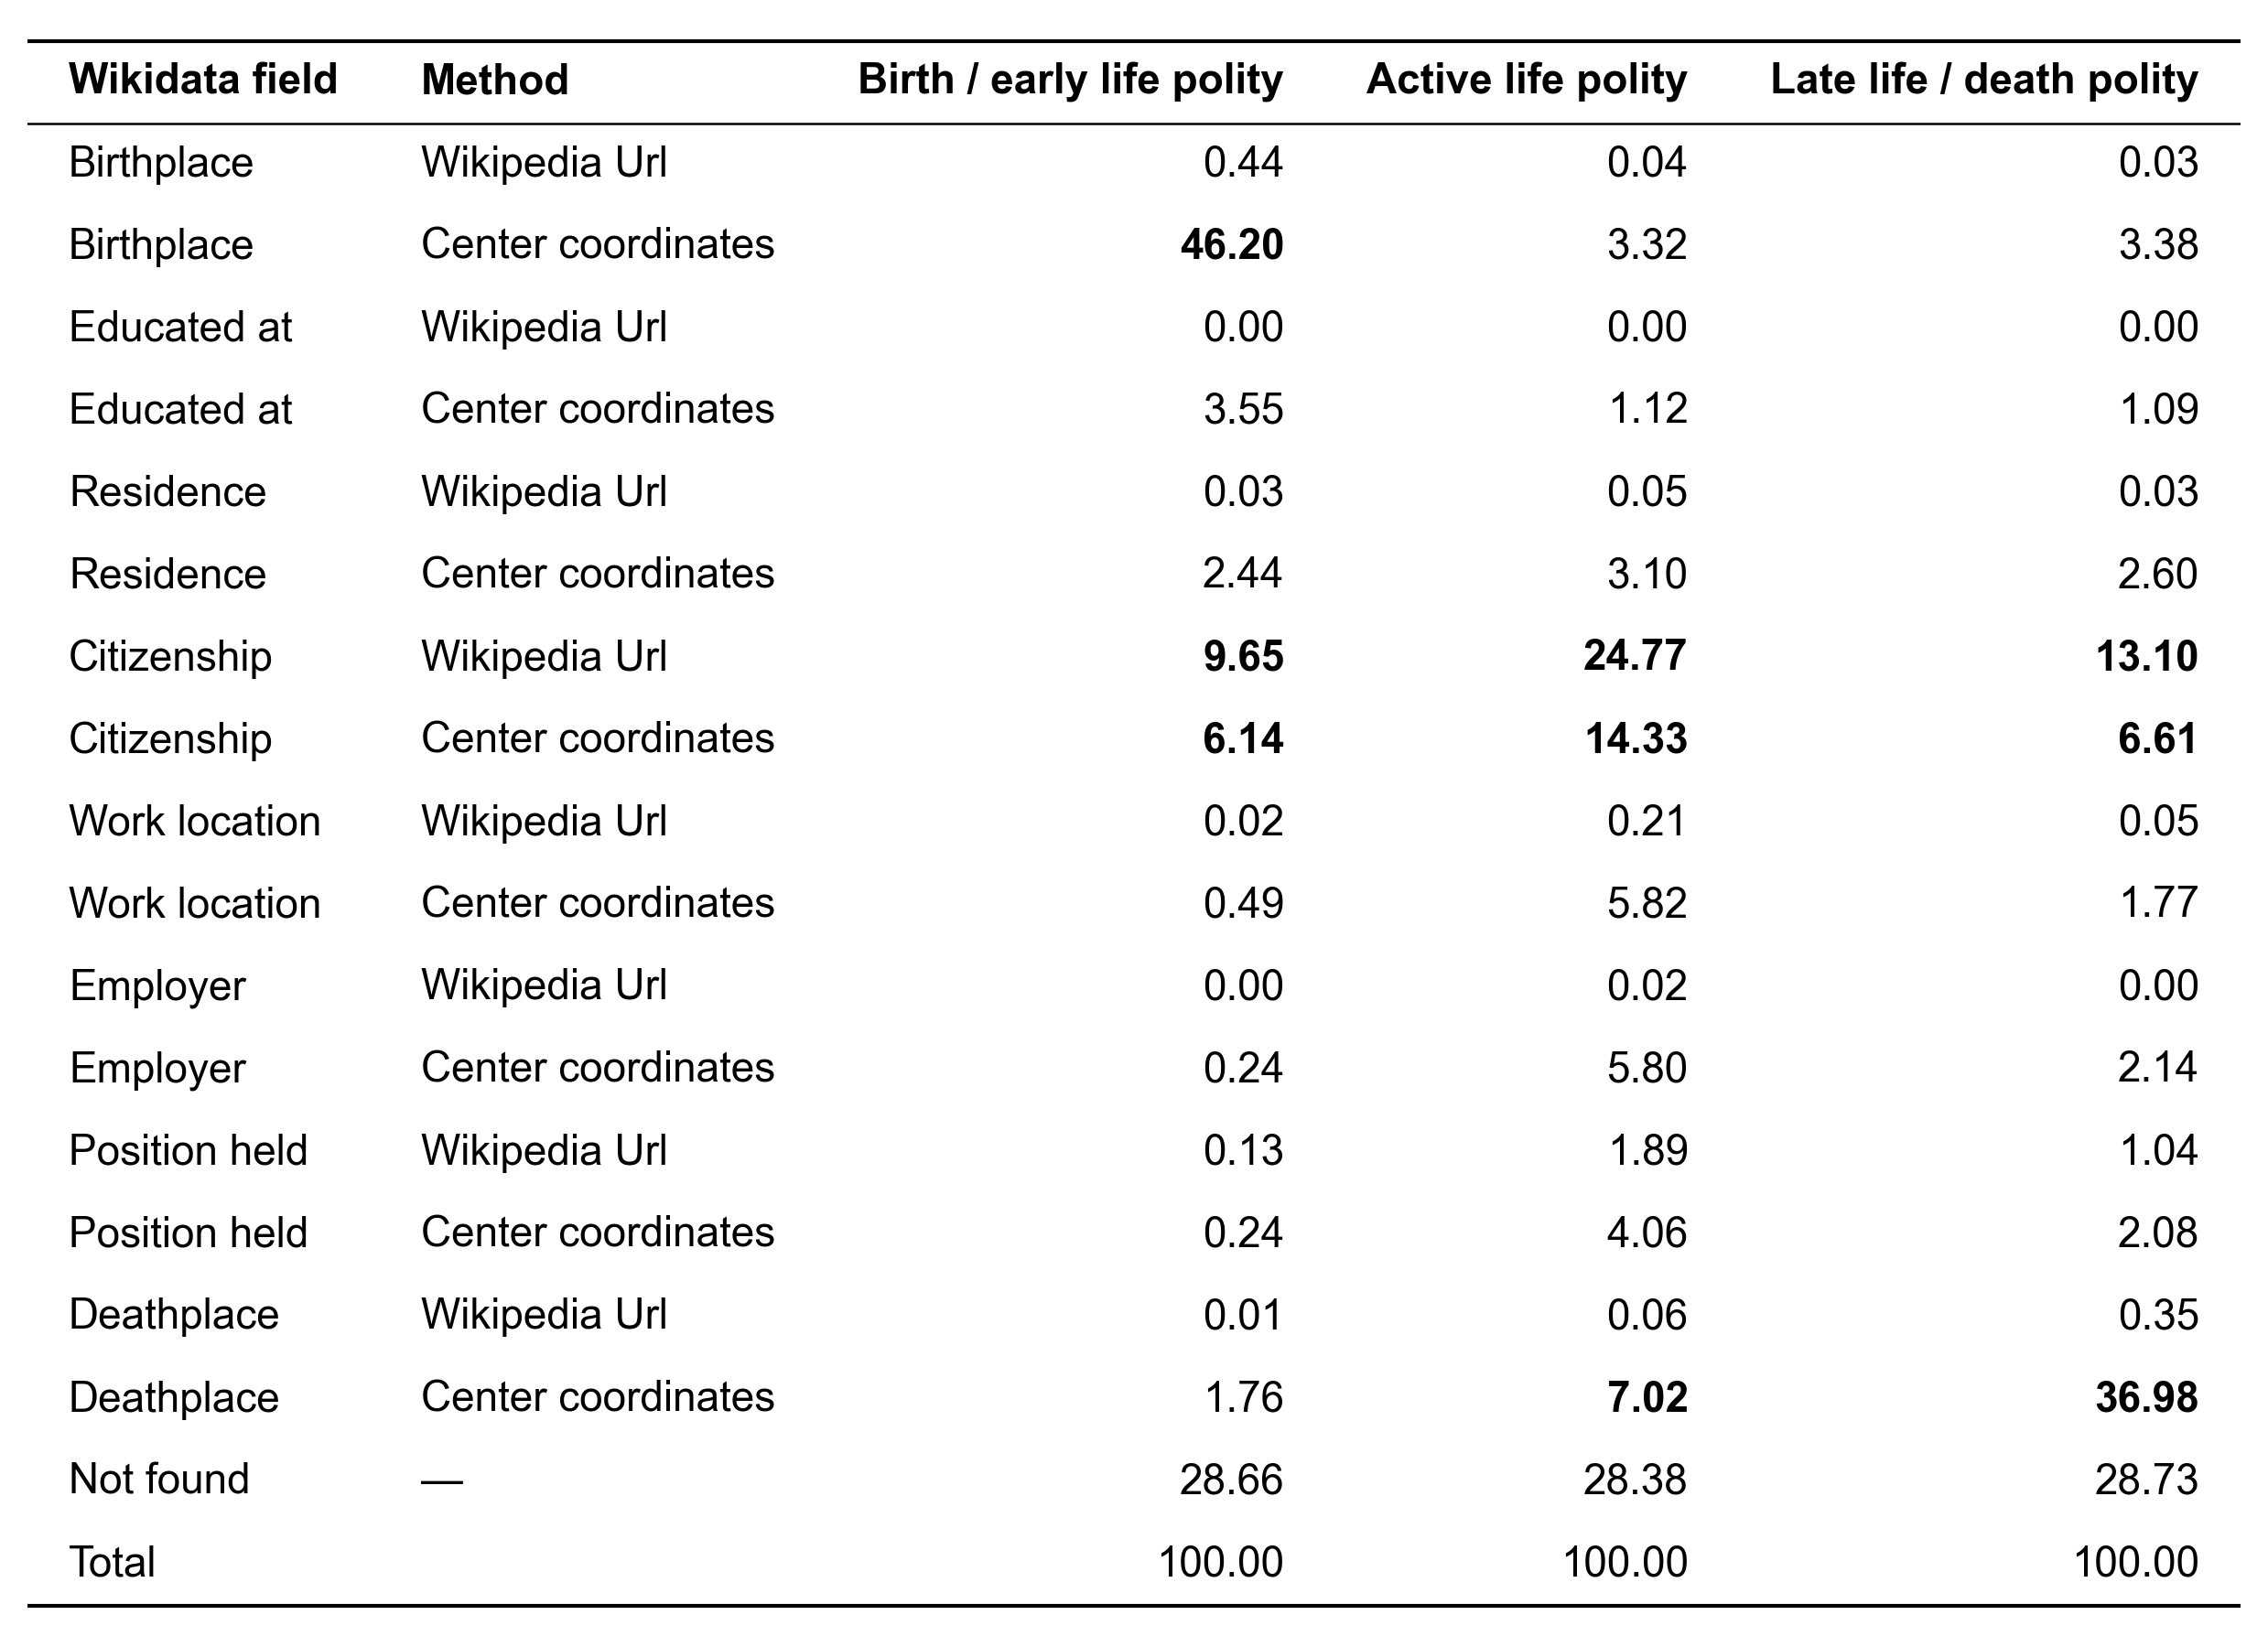

In [3]:
found_by = (
    stages.with_columns(
        field=pl.col('wikidata_field').fill_null('not found'),
        method=pl.col('method').fill_null('—'),
        individuals=pl.len().over('stage'),
    )
    .group_by('stage', 'field', 'method').agg(share=100 * pl.len() / pl.col('individuals').first())
    .pivot(on='stage', index=['field', 'method'], values='share')
    .with_columns(pl.col(STAGES).fill_null(0.0))
    .sort(pl.col('field').replace_strict({name: rank for rank, name in enumerate(FIELDS)}), pl.col('method').replace_strict({name: rank for rank, name in enumerate(METHODS)}))
    .select('field', 'method', *STAGES)
)
total = found_by.select(pl.lit('total').alias('field'), pl.lit('').alias('method'), pl.col(STAGES).sum())
columns = {'early': 'Birth / early life polity', 'active': 'Active life polity', 'late': 'Late life / death polity'}
ranked = found_by.with_columns(pl.when(pl.col('field') == 'not found').then(None).otherwise(pl.col(stage)).alias(stage) for stage in STAGES)
top_three = {(row, columns[stage]) for stage in STAGES for row in ranked[stage].arg_sort(descending=True, nulls_last=True)[:3].to_list()}

table = pl.concat([found_by, total]).with_columns(
    pl.col('field').str.slice(0, 1).str.to_uppercase() + pl.col('field').str.slice(1),
    pl.col('method').replace(METHODS),
    pl.col(STAGES).map_elements(lambda share: f'{share:.2f}' if share else '', return_dtype=pl.String),
)
show_table(table.rename({'field': 'Wikidata field', 'method': 'Method', **columns}), bold_cells=top_three)

## Ten well-known individuals who moved
Their polity at each life stage, with the stage years in brackets; the late life / death polity is the death year alone when the work period runs to the death. Only individuals whose birth and death years come from Wikidata, not imputed, and with at most three polities per stage.

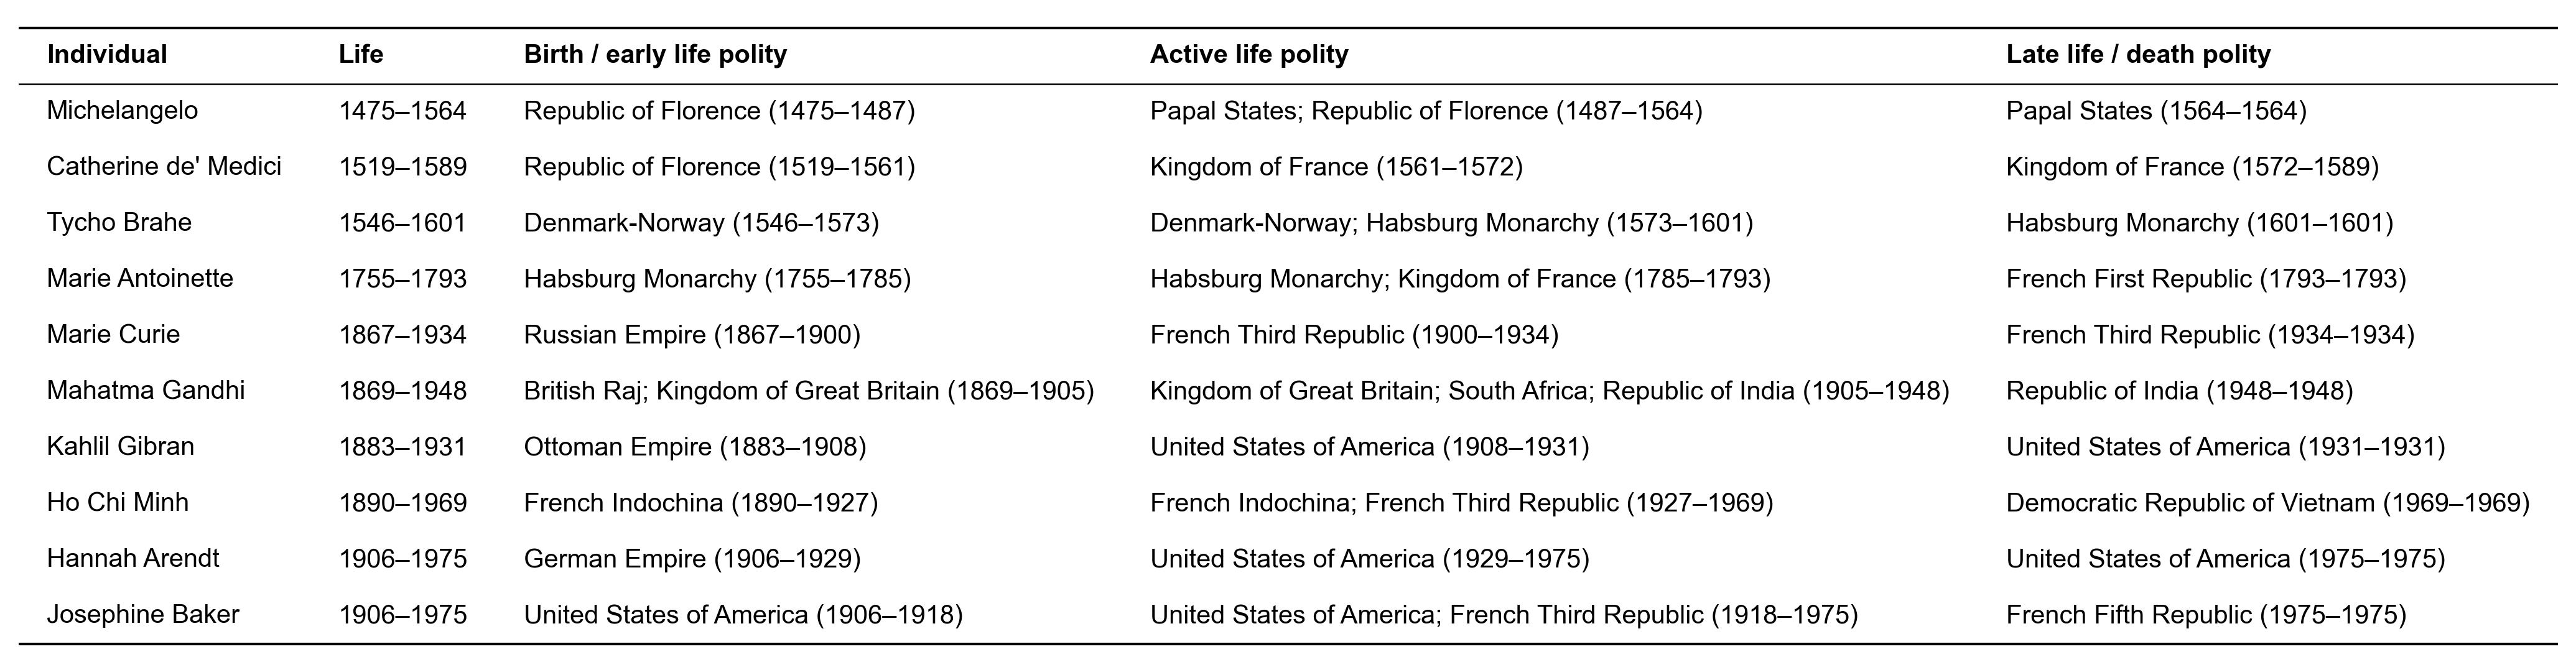

In [4]:
connection = duckdb.connect(DB_PATH, read_only=True)
dates = connection.sql(f'''
    SELECT entity.qid AS qid, birth_date.year AS birth, death_date.year AS death
    FROM individual_enriched
    WHERE entity.qid IN {tuple(EXAMPLES)} AND birth_date.iso IS NOT NULL AND death_date.iso IS NOT NULL
''').pl()
assert dates.height == len(EXAMPLES), 'an example has an imputed birth or death date'

example_stages = (
    pl.read_parquet(EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'start_year', 'end_year', 'polities'])
    .filter(pl.col('qid').is_in(list(EXAMPLES)), pl.col('polities').list.len() > 0)
)
assert example_stages['polities'].list.len().max() <= MAX_POLITIES, 'an example has more than three polities in a stage'
examples = (
    example_stages.with_columns(cell=pl.format('{} ({}–{})', pl.col('polities').list.join('; '), 'start_year', 'end_year'))
    .pivot(on='stage', index='qid', values='cell')
)
people = (
    dates.join(examples, on='qid', how='left')
    .with_columns(pl.col(stage).fill_null('—') if stage in examples.columns else pl.lit('—').alias(stage) for stage in STAGES)
    .with_columns(name=pl.col('qid').replace_strict(EXAMPLES), life=pl.format('{}–{}', 'birth', 'death'))
    .sort('birth')
)
show_table(people.select(pl.col('name').alias('Individual'), pl.col('life').alias('Life'), *[pl.col(stage).alias(columns[stage]) for stage in STAGES]), font_size=10)